# Lezione 10 — Notebook docente — Caso TakeHome

## Prompt 0 — inizializzazione e vincoli generali

Caso: **Lehman Brothers 2008: rischio sistemico, migrazioni creditizie e perdita di portafoglio**.

Il notebook docente rende osservabile la sequenza normativa:

**Prompt 0 → Prompt 1 → Prompt 2 → Prompt 3 → sei prompt di tappa**.

La Scheda Caso resta vincolante. Il confronto è ex ante e didattico: non usa informazione successiva al giugno 2008 e non sostituisce i parametri assegnati con dati storici esterni.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

def draw_next_1d(current, P, rng):
    """Estrae lo stato successivo per molte repliche da una matrice di transizione."""
    u = rng.random(current.shape[0])
    out = np.empty_like(current)
    cdf = np.cumsum(P, axis=1)
    for k in range(P.shape[0]):
        mask = current == k
        if np.any(mask):
            out[mask] = np.searchsorted(cdf[k], u[mask], side="right")
    return out

def draw_next_by_regime(current, regime, matrices, rng):
    """Migrazioni individuali, condizionate a un regime comune per replica."""
    u = rng.random(current.shape)
    out = np.empty_like(current)
    for m, P in enumerate(matrices):
        cdf = np.cumsum(P, axis=1)
        reg_mask = regime == m
        if not np.any(reg_mask):
            continue
        for k in range(P.shape[0]):
            mask = reg_mask[:, None] & (current == k)
            if np.any(mask):
                out[mask] = np.searchsorted(cdf[k], u[mask], side="right")
    return out

def empirical_var_cvar(losses, alpha):
    """
    VaR empirico come quantile sinistro discreto e CVaR coerente con
    CVaR_alpha = q + E[(L-q)_+]/(1-alpha).
    Questa formula gestisce correttamente anche la massa sul VaR.
    """
    x = np.asarray(losses, dtype=float)
    q = np.quantile(x, alpha, method="higher")
    cvar = q + np.maximum(x - q, 0.0).mean() / (1.0 - alpha)
    return float(q), float(cvar)

def risk_summary(losses):
    x = np.asarray(losses, dtype=float)
    v95, c95 = empirical_var_cvar(x, 0.95)
    v99, c99 = empirical_var_cvar(x, 0.99)
    return {
        "Perdita media": x.mean(),
        "Varianza": x.var(ddof=0),
        "Deviazione standard": x.std(ddof=0),
        "VaR 95%": v95,
        "CVaR 95%": c95,
        "VaR 99%": v99,
        "CVaR 99%": c99,
    }

NOTEBOOK_ROLE = "docente"
CASE_ID = "Lezione 10 - Caso TakeHome - Lehman Brothers"
print(CASE_ID)
print("Ambiente inizializzato; specifica teorica preservata.")

Lezione 10 - Caso TakeHome - Lehman Brothers
Ambiente inizializzato; specifica teorica preservata.


## Prompt 1 — cella iniziale di inquadramento del caso

**Contesto e domanda quantitativa.** Nel giugno 2008 si considera un portafoglio di 40 debitori con investimento complessivo di 173 milioni e una posizione Lehman Brothers di 25 milioni. Il regime sistemico comune $M_t\in\{O,S,C\}$ evolve trimestralmente e determina la matrice di migrazione. Condizionatamente alla traiettoria sistemica le migrazioni dei debitori sono indipendenti.

Il controfattuale elimina Lehman e redistribuisce i 25 milioni proporzionalmente sui 39 debitori residui, moltiplicandone gli investimenti per $173/148$. Il confronto usa la stessa traiettoria sistemica e le stesse traiettorie creditizie dei 39 debitori comuni.

**Quantità da stimare/calcolare.**
- Perdita media, varianza, deviazione standard.
- VaR e CVaR al 95% e 99%.
- Probabilità di ingresso almeno una volta in $C$.
- Perdita media del portafoglio concentrato con/senza ingresso in $C$.
- Differenze $\Delta\rho=\rho(L^P_{\mathrm{div}})-\rho(L^P_{\mathrm{conc}})$.
- $\Delta L^{(r)}=L_{\mathrm{div}}^{P,(r)}-L_{\mathrm{conc}}^{P,(r)}$.

**Output richiesti.**
1. Tabella 1 — portafoglio iniziale concentrato.
2. Tabella 2 — portafoglio controfattuale.
3. Tabella 3 — misure di rischio.
4. Tabella 4 — regime sistemico e perdita.
5. Figura 1 — distribuzione del portafoglio concentrato con VaR 95% e 99%.
6. Figura 2 — confronto delle distribuzioni, con attenzione alla coda destra.
7. Figura 3 — perdite del concentrato con/senza ingresso in crisi.

**Controlli.** Sono conservate categorie e numerazione della Scheda Caso: matrici stocastiche; $D$ assorbente; domini degli stati; traiettoria sistemica comune; estrazioni individuali; numerosità 40/39; totale 173; proporzioni residue preservate; stesse traiettorie dei 39 debitori; additività; seed 2026; VaR/CVaR monetari; stabilità empirica.

La Scheda Caso non viene modificata.

In [2]:
CASE = {
    "n_concentrated": 40,
    "n_counterfactual": 39,
    "total_investment": 173.0,
    "lehman_investment": 25.0,
    "N_MC": 50_000,
    "T": 4,
    "seed": 2026,
    "system_states": ["O", "S", "C"],
    "credit_states": ["A", "BBB", "BB", "B", "D"],
}
display(pd.Series(CASE, name="Specifiche vincolanti"))

n_concentrated                       40
n_counterfactual                     39
total_investment               173.0000
lehman_investment               25.0000
N_MC                              50000
T                                     4
seed                               2026
system_states                 [O, S, C]
credit_states        [A, BBB, BB, B, D]
Name: Specifiche vincolanti, dtype: object

## Prompt 2 — Flusso logico-teorico risolutivo validato

| Passo | Finalità risolutiva | Formula / proprietà | Applicazione | Output o controllo |
|---:|---|---|---|---|
| 1 | Definire processi e dipendenza | $M_t\in\{O,S,C\}$, $M_0=S$, $Q$; $P^{(m)}$; $D$ assorbente; indipendenza condizionata | Regole di transizione sistemiche e individuali | controlli matrici, domini, struttura comune |
| 2 | Definire portafogli e perdita | $L_i=V_{i,0}\varphi(X_{i,0},X_{i,4})$; EAD=$V_{i,0}$; LGD=0.65; $V_i^{div}=V_i173/148$ | concentrato 40 e controfattuale 39 | numerosità, totale 173, proporzioni |
| 3 | Generare repliche accoppiate | $N_{MC}=50\,000$, seed 2026 | stesse traiettorie per i 39 debitori comuni | CRN e riproducibilità |
| 4 | Analizzare il regime sistemico | $I_C=\mathbf 1_{\{\exists t:M_t=C\}}$ | separazione repliche con/senza crisi | probabilità di crisi, Tabella 4, Figura 3 |
| 5 | Stimare e confrontare il rischio | media, varianza, $\sigma$, VaR, CVaR | misure per entrambi e $\Delta\rho$ | Tabella 3, Figure 1–2, stabilità |
| 6 | Valutare $\Delta L$ e chiudere i controlli | $\Delta L=L_{\mathrm{div}}-L_{\mathrm{conc}}$ | distribuzione delle differenze | sintesi controlli e base per interpretazione |

In [3]:
FLOW_STEPS = pd.DataFrame({
    "Passo": range(1, 7),
    "Nucleo": [
        "Processi stocastici e dipendenza",
        "Portafogli e funzione di perdita",
        "Repliche Monte Carlo accoppiate",
        "Ruolo del regime sistemico",
        "Misure di rischio",
        "Differenza replica per replica e controlli",
    ]
})
display(FLOW_STEPS)

,Passo,Nucleo
0,1,Processi stocastici e dipendenza
1,2,Portafogli e funzione di perdita
2,3,Repliche Monte Carlo accoppiate
3,4,Ruolo del regime sistemico
4,5,Misure di rischio
5,6,Differenza replica per replica e controlli


## Prompt 3 — Scomposizione input-output validata

| Tappa | Titolo | Input | Operazione | Output | Controllo | Uso successivo | Regime |
|---:|---|---|---|---|---|---|:---:|
| 1 | Parametri e strutture | $Q$, $P^{(m)}$, $\varphi$, LGD, $N_{MC}$, $T$, seed | inizializzare calibrazione | strutture dati | righe=1, $D$ assorbente, domini | portafogli/simulazione | B |
| 2 | Due portafogli | composizione, Lehman 25, fattore 173/148 | costruire concentrato e controfattuale | Tabelle 1–2 | 40/39, totale 173, proporzioni | perdite | B |
| 3 | Traiettorie | seed 2026, $M_0=S$, $Q$, $P^{(m)}$ | simulare regime comune e rating | $M,X$ | struttura comune, indipendenza condizionata, CRN | perdite | B |
| 4 | Perdite | stati finali, investimenti, $\varphi$ | applicare tassi migration/default e aggregare | $L_{conc},L_{div},\Delta L$ | additività e accoppiamento | rischio | B |
| 5 | Rischio e sistema | campioni, $M$ | statistiche, VaR/CVaR, condizionamento | Tabelle 3–4 | CVaR quantile-based, stabilità | grafici | B |
| 6 | Grafici e controlli | tutti gli output | Figure 1–3, $\Delta L$, sintesi | grafici + controlli | coerenza complessiva | interpretazione docente | B |

In [4]:
STAGES = [
    "Parametri e strutture del modello",
    "Costruzione dei due portafogli",
    "Simulazione delle traiettorie sistemiche e creditizie",
    "Perdite individuali e aggregate",
    "Misure di rischio e analisi del regime sistemico",
    "Rappresentazione grafica e controlli conclusivi",
]
display(pd.DataFrame({"Tappa": range(1, 7), "Titolo": STAGES}))

,Tappa,Titolo
0,1,Parametri e strutture del modello
1,2,Costruzione dei due portafogli
2,3,Simulazione delle traiettorie sistemiche e cre...
3,4,Perdite individuali e aggregate
4,5,Misure di rischio e analisi del regime sistemico
5,6,Rappresentazione grafica e controlli conclusivi


## Prompt di tappa 1 — Parametri e strutture del modello (Regime B)

**Input:** $Q$, $P^{(O)}$, $P^{(S)}$, $P^{(C)}$, $\varphi$, LGD=0.65, $N_{MC}=50\,000$, $T=4$, seed 2026.

**Output:** strutture NumPy/Pandas contenenti la calibrazione vincolante.

**Controlli 1–4:** somme di riga; default assorbente; domini degli stati.

In [5]:
system_states = ["O", "S", "C"]
credit_states = ["A", "BBB", "BB", "B", "D"]

Q = np.array([
    [0.82, 0.16, 0.02],
    [0.30, 0.55, 0.15],
    [0.10, 0.35, 0.55],
])
P_O = np.array([
    [0.960,0.035,0.004,0.0005,0.0005],
    [0.020,0.940,0.030,0.0070,0.0030],
    [0.004,0.030,0.910,0.0460,0.0100],
    [0.001,0.004,0.025,0.9400,0.0300],
    [0,0,0,0,1],
])
P_S = np.array([
    [0.920,0.060,0.014,0.004,0.002],
    [0.010,0.870,0.085,0.027,0.008],
    [0.002,0.018,0.820,0.135,0.025],
    [0,0.002,0.018,0.880,0.100],
    [0,0,0,0,1],
])
P_C = np.array([
    [0.820,0.120,0.040,0.015,0.005],
    [0.005,0.760,0.150,0.060,0.025],
    [0,0.010,0.680,0.230,0.080],
    [0,0.001,0.009,0.740,0.250],
    [0,0,0,0,1],
])
P_regime = [P_O, P_S, P_C]

phi = np.array([
    [0.00,0.03,0.10,0.22,0.65],
    [-0.02,0.00,0.06,0.16,0.65],
    [-0.04,-0.02,0.00,0.09,0.65],
    [-0.06,-0.04,-0.02,0.00,0.65],
])
LGD = 0.65
N_MC, T, SEED = 50_000, 4, 2026

row_checks = {
    "Q": np.allclose(Q.sum(1),1),
    "P_O": np.allclose(P_O.sum(1),1),
    "P_S": np.allclose(P_S.sum(1),1),
    "P_C": np.allclose(P_C.sum(1),1),
}
absorbing = all(np.allclose(P[-1], [0,0,0,0,1]) for P in P_regime)
display(pd.Series(row_checks, name="Somme di riga = 1"))
print("D assorbente:", absorbing)
print("Domini:", system_states, credit_states)
assert all(row_checks.values()) and absorbing

Q      True
P_O    True
P_S    True
P_C    True
Name: Somme di riga = 1, dtype: bool

D assorbente: True
Domini: ['O', 'S', 'C'] ['A', 'BBB', 'BB', 'B', 'D']


## Prompt di tappa 2 — Costruzione dei due portafogli (Regime B)

**Input:** 40 debitori, investimento totale 173, Lehman 25; portafoglio controfattuale ottenuto eliminando Lehman e moltiplicando ogni investimento residuo per $173/148$.

**Output:** Tabelle 1 e 2 e vettori monetari.

**Controlli 7–10:** numerosità 40/39; totale 173 in entrambi; proporzioni relative dei 39 debitori preservate.

In [6]:
names = (["Lehman Brothers"] +
         [f"A_{i+1:02d}" for i in range(11)] +
         [f"BBB_{i+1:02d}" for i in range(14)] +
         [f"BB_{i+1:02d}" for i in range(9)] +
         [f"B_{i+1:02d}" for i in range(5)])
rating0 = np.array([0] + [0]*11 + [1]*14 + [2]*9 + [3]*5, dtype=np.int8)
V_conc = np.array([25] + [5]*11 + [4]*14 + [3]*9 + [2]*5, dtype=float)
V_div = V_conc[1:] * (173.0/148.0)

portfolio_conc = pd.DataFrame({
    "Debitore": names,
    "Rating iniziale": np.array(credit_states)[rating0],
    "Investimento": V_conc,
})
portfolio_div = pd.DataFrame({
    "Debitore": names[1:],
    "Rating iniziale": np.array(credit_states)[rating0[1:]],
    "Investimento": V_div,
})

tab1 = (portfolio_conc.groupby("Rating iniziale", sort=False)
        .agg(N=("Debitore","size"), Investimento_individuale=("Investimento","first"),
             Investimento_complessivo=("Investimento","sum")))
tab2 = (portfolio_div.groupby("Rating iniziale", sort=False)
        .agg(N=("Debitore","size"), Investimento_individuale=("Investimento","first"),
             Investimento_complessivo=("Investimento","sum")))
print("Tabella 1 — Portafoglio concentrato")
display(tab1)
print("Tabella 2 — Portafoglio controfattuale")
display(tab2)

assert len(V_conc) == 40 and len(V_div) == 39
assert np.isclose(V_conc.sum(), 173) and np.isclose(V_div.sum(), 173)
assert np.allclose(V_div / V_conc[1:], 173/148)
print("Controlli di numerosità, totale e proporzioni: OK")

Tabella 1 — Portafoglio concentrato


,N,Investimento_individuale,Investimento_complessivo
Rating iniziale,,,
A,12,25.0000,80.0000
BBB,14,4.0000,56.0000
BB,9,3.0000,27.0000
B,5,2.0000,10.0000


Tabella 2 — Portafoglio controfattuale


,N,Investimento_individuale,Investimento_complessivo
Rating iniziale,,,
A,11,5.8446,64.2905
BBB,14,4.6757,65.4595
BB,9,3.5068,31.5608
B,5,2.3378,11.6892


Controlli di numerosità, totale e proporzioni: OK


## Prompt di tappa 3 — Simulazione delle traiettorie sistemiche e creditizie (Regime B)

**Input:** seed 2026, $N_{MC}=50\,000$, $T=4$, $M_0=S$, $Q$, $P^{(m)}$, rating iniziali.

**Operazione:** simulare una sola traiettoria sistemica per replica e, condizionatamente a essa, le traiettorie dei 40 debitori con estrazioni individuali. Le traiettorie dei 39 debitori comuni sono riutilizzate nel controfattuale.

**Controlli 5, 6, 11, 13:** regime comune, estrazioni individuali, identità delle traiettorie comuni, seed. Le prime tre proprietà sono garantite **PER COSTRUZIONE** dalla struttura degli oggetti simulati.

In [7]:
rng = np.random.default_rng(SEED)

M_sim = np.empty((N_MC, T), dtype=np.int8)
M_sim[:,0] = 1  # S
for t in range(T-1):
    M_sim[:,t+1] = draw_next_1d(M_sim[:,t], Q, rng)

X_sim = np.tile(rating0, (N_MC,1)).astype(np.int8)
for t in range(T):
    X_sim = draw_next_by_regime(X_sim, M_sim[:,t], P_regime, rng)

assert np.all(M_sim[:,0] == 1)
assert np.all((M_sim >= 0) & (M_sim < 3))
assert np.all((X_sim >= 0) & (X_sim < 5))
print("Shape regimi:", M_sim.shape)
print("Shape rating finali:", X_sim.shape)
print("Seed impostato:", SEED)
print("Traiettoria sistemica unica: PER COSTRUZIONE")
print("Estrazioni individuali condizionate: PER COSTRUZIONE")
print("Traiettorie dei 39 debitori comuni riutilizzabili: PER COSTRUZIONE")

Shape regimi: (50000, 4)
Shape rating finali: (50000, 40)
Seed impostato: 2026
Traiettoria sistemica unica: PER COSTRUZIONE
Estrazioni individuali condizionate: PER COSTRUZIONE
Traiettorie dei 39 debitori comuni riutilizzabili: PER COSTRUZIONE


## Prompt di tappa 4 — Perdite individuali e aggregate (Regime B)

**Input:** stati finali $X_{i,4}$, investimenti dei due portafogli e funzione $\varphi$.

**Operazione:** applicare

$$
L_i=V_{i,0}\varphi(X_{i,0},X_{i,4}),
$$

con $\varphi(r_0,D)=0.65$, quindi aggregare. Il controfattuale usa gli stessi stati finali dei 39 debitori residui.

**Output:** $L_{\mathrm{conc}}^P$, $L_{\mathrm{div}}^P$, $\Delta L$.

**Controllo 12:** additività replica per replica; accoppiamento dei debitori comuni.

In [8]:
initial_matrix = np.broadcast_to(rating0, (N_MC, len(rating0)))
loss_rate = phi[initial_matrix, X_sim]

L_ind_conc = loss_rate * V_conc
L_conc = L_ind_conc.sum(axis=1)

# Debitori comuni = colonne 1:40; stessi stati finali, nuovi investimenti.
L_ind_div = loss_rate[:,1:] * V_div
L_div = L_ind_div.sum(axis=1)
delta_L = L_div - L_conc

assert np.allclose(L_conc, L_ind_conc.sum(1))
assert np.allclose(L_div, L_ind_div.sum(1))
assert np.allclose(delta_L, L_div - L_conc)
assert np.allclose(loss_rate[:,1:], phi[initial_matrix[:,1:], X_sim[:,1:]])
print("Additività concentrato: OK")
print("Additività controfattuale: OK")
print("Stesse traiettorie dei 39 debitori comuni: PER COSTRUZIONE")

Additività concentrato: OK
Additività controfattuale: OK
Stesse traiettorie dei 39 debitori comuni: PER COSTRUZIONE


## Prompt di tappa 5 — Misure di rischio e analisi del regime sistemico (Regime B)

**Input:** $L_{\mathrm{conc}}^P$, $L_{\mathrm{div}}^P$, traiettorie $M$.

**Operazione:** stimare media, varianza, deviazione standard, VaR e CVaR. Per la distribuzione empirica discreta:

$$
CVaR_\alpha=q_\alpha+\frac{1}{1-\alpha}\mathbb E[(L-q_\alpha)_+],
$$

evitando la scorciatoia della semplice media delle osservazioni $\ge VaR$ quando la massa sul quantile eccede quella necessaria per la coda $1-\alpha$.

**Output:** Tabelle 3 e 4; $\Delta\rho$; probabilità di crisi; perdite medie condizionate.

**Controlli 14–15:** misure sulle perdite monetarie e stabilità empirica al variare della numerosità Monte Carlo.

In [9]:
s_conc = risk_summary(L_conc)
s_div = risk_summary(L_div)
risk_table = pd.DataFrame({"Concentrato": s_conc, "Controfattuale": s_div})
risk_table["Delta (div-conc)"] = risk_table["Controfattuale"] - risk_table["Concentrato"]

hit_C = (M_sim == 2).any(axis=1)
system_table = pd.DataFrame({
    "Gruppo repliche": ["Senza ingresso in C", "Con ingresso in C"],
    "Numero repliche": [(~hit_C).sum(), hit_C.sum()],
    "Perdita media concentrato": [L_conc[~hit_C].mean(), L_conc[hit_C].mean()],
})
print("Tabella 3 — Misure di rischio")
display(risk_table)
print("Tabella 4 — Regime sistemico e perdita")
display(system_table)
print(f"Probabilità di ingresso in C: {hit_C.mean():.4%}")

half = 25_000
stable = pd.DataFrame({
    "Conc completo": risk_summary(L_conc),
    "Conc prime 25k": risk_summary(L_conc[:half]),
    "Div completo": risk_summary(L_div),
    "Div prime 25k": risk_summary(L_div[:half]),
})
print("Controllo empirico di stabilità")
display(stable.loc[["Perdita media","Deviazione standard","VaR 95%","CVaR 95%","VaR 99%","CVaR 99%"]])

Tabella 3 — Misure di rischio


,Concentrato,Controfattuale,Delta (div-conc)
Perdita media,11.1052,12.1626,1.0574
Varianza,47.8854,52.8083,4.9228
Deviazione standard,6.9199,7.2669,0.3470
VaR 95%,24.8000,26.5929,1.7929
CVaR 95%,29.6367,30.8784,1.2417
VaR 99%,32.5400,33.8402,1.3002
CVaR 99%,37.0826,36.9024,-0.1802


Tabella 4 — Regime sistemico e perdita


,Gruppo repliche,Numero repliche,Perdita media concentrato
0,Senza ingresso in C,35235,8.1062
1,Con ingresso in C,14765,18.2621


Probabilità di ingresso in C: 29.5300%
Controllo empirico di stabilità


,Conc completo,Conc prime 25k,Div completo,Div prime 25k
Perdita media,11.1052,11.1209,12.1626,12.1870
Deviazione standard,6.9199,6.9164,7.2669,7.2855
VaR 95%,24.8000,24.8200,26.5929,26.6747
CVaR 95%,29.6367,29.6154,30.8784,30.9789
VaR 99%,32.5400,32.6500,33.8402,33.8986
CVaR 99%,37.0826,36.9061,36.9024,36.9783


## Prompt di tappa 6 — Rappresentazione grafica, $\Delta L$ e controlli conclusivi (Regime B)

**Input:** distribuzioni simulate, $\Delta L$, indicatore di crisi e risultati precedenti.

**Output:** Figure 1–3; descrizione di $\Delta L$; ricognizione dei controlli 1–15.

**Controllo:** coerenza tra campioni, tabelle, grafici e differenze replica per replica.

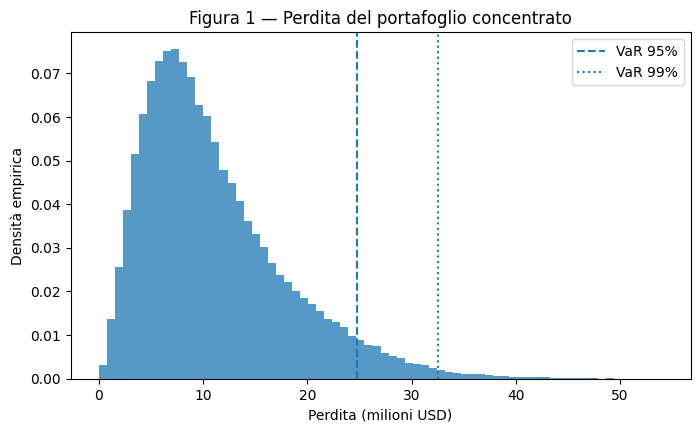

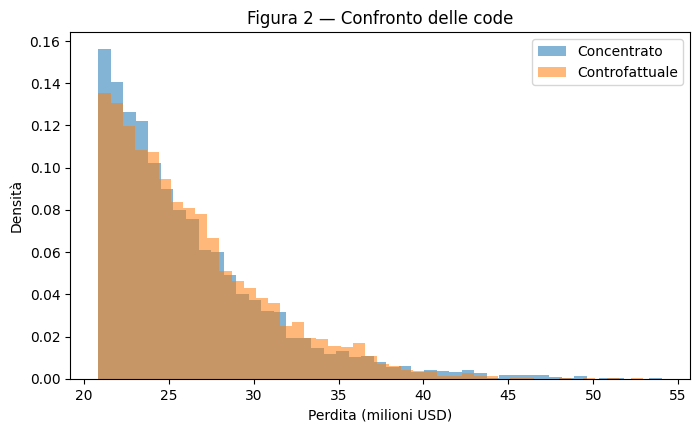

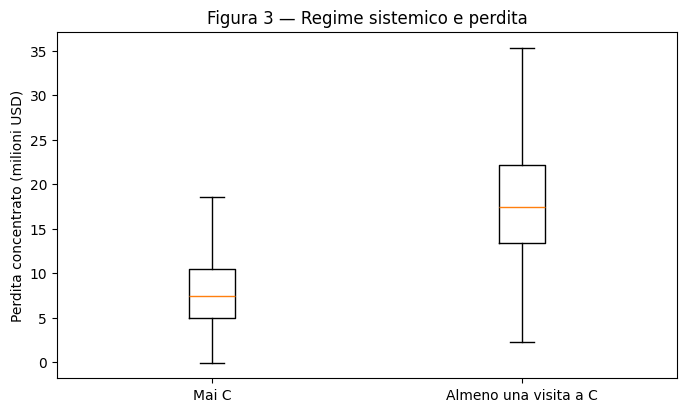

Media Delta L       1.0574
Mediana Delta L     1.2508
P(Delta L > 0)      0.8946
Min               -16.1470
Max                 7.6520
Name: Distribuzione Delta L, dtype: float64

,Esito
Q e P con righe che sommano a 1,True
D assorbente,True
Stati nei domini,True
Portafoglio concentrato = 40,True
Portafoglio controfattuale = 39,True
Totale concentrato = 173,True
Totale controfattuale = 173,True
Proporzioni residue preservate,True
Additività concentrato,True
Additività controfattuale,True


In [10]:
fig, ax = plt.subplots(figsize=(8,4.5))
ax.hist(L_conc, bins=70, density=True, alpha=0.75)
ax.axvline(s_conc["VaR 95%"], linestyle="--", label="VaR 95%")
ax.axvline(s_conc["VaR 99%"], linestyle=":", label="VaR 99%")
ax.set(title="Figura 1 — Perdita del portafoglio concentrato",
       xlabel="Perdita (milioni USD)", ylabel="Densità empirica")
ax.legend()
plt.show()

cut = min(np.quantile(L_conc,.90), np.quantile(L_div,.90))
fig, ax = plt.subplots(figsize=(8,4.5))
ax.hist(L_conc[L_conc >= cut], bins=45, density=True, alpha=0.55, label="Concentrato")
ax.hist(L_div[L_div >= cut], bins=45, density=True, alpha=0.55, label="Controfattuale")
ax.set(title="Figura 2 — Confronto delle code",
       xlabel="Perdita (milioni USD)", ylabel="Densità")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8,4.5))
ax.boxplot([L_conc[~hit_C], L_conc[hit_C]], tick_labels=["Mai C","Almeno una visita a C"], showfliers=False)
ax.set(title="Figura 3 — Regime sistemico e perdita", ylabel="Perdita concentrato (milioni USD)")
plt.show()

delta_desc = pd.Series({
    "Media Delta L": delta_L.mean(),
    "Mediana Delta L": np.median(delta_L),
    "P(Delta L > 0)": np.mean(delta_L > 0),
    "Min": delta_L.min(),
    "Max": delta_L.max(),
}, name="Distribuzione Delta L")
display(delta_desc)

controls = pd.Series({
    "Q e P con righe che sommano a 1": all(row_checks.values()),
    "D assorbente": absorbing,
    "Stati nei domini": bool(np.all((M_sim>=0)&(M_sim<3)) and np.all((X_sim>=0)&(X_sim<5))),
    "Portafoglio concentrato = 40": len(V_conc)==40,
    "Portafoglio controfattuale = 39": len(V_div)==39,
    "Totale concentrato = 173": bool(np.isclose(V_conc.sum(),173)),
    "Totale controfattuale = 173": bool(np.isclose(V_div.sum(),173)),
    "Proporzioni residue preservate": bool(np.allclose(V_div/V_conc[1:],173/148)),
    "Additività concentrato": bool(np.allclose(L_conc,L_ind_conc.sum(1))),
    "Additività controfattuale": bool(np.allclose(L_div,L_ind_div.sum(1))),
    "Seed configurato=2026": SEED==2026,
    "Traiettoria sistemica unica": "PER COSTRUZIONE",
    "Indipendenza condizionata": "PER COSTRUZIONE",
    "Stesse traiettorie 39 debitori": "PER COSTRUZIONE",
    "Stabilità MC": "VERIFICA EMPIRICA riportata sopra",
})
display(controls.to_frame("Esito"))

## Interpretazione docente di riferimento e limiti

Il fattore sistemico comune produce una netta separazione tra repliche che visitano la crisi e repliche che non la visitano. Il controfattuale non è un puro esperimento di “deconcentrazione”: eliminare Lehman e riallocare proporzionalmente i 25 milioni modifica anche l'esposizione complessiva alle classi BBB, BB e B.

Con la calibrazione assegnata, la riallocazione può aumentare perdita attesa e varie misure di rischio pur riducendo leggermente una misura estrema di coda. Questo impedisce una conclusione meccanica secondo cui rimuovere la posizione più grande riduca necessariamente tutte le metriche. I risultati sono proprietà del modello didattico ex ante e non una previsione retrospettiva del default di Lehman.

In [11]:
benchmark = pd.DataFrame({
    "Output notebook": [
        s_conc["Perdita media"], s_conc["Deviazione standard"], s_conc["VaR 95%"],
        s_conc["CVaR 95%"], s_conc["VaR 99%"], s_conc["CVaR 99%"],
        s_div["Perdita media"], s_div["Deviazione standard"], s_div["VaR 95%"],
        s_div["CVaR 95%"], s_div["VaR 99%"], s_div["CVaR 99%"],
    ],
    "Benchmark indicativo scheda": [
        11.11,6.92,24.73,29.69,32.78,37.54,
        12.16,7.26,26.56,30.92,33.66,37.03,
    ],
}, index=[
    "Conc media","Conc sd","Conc VaR95","Conc CVaR95","Conc VaR99","Conc CVaR99",
    "Div media","Div sd","Div VaR95","Div CVaR95","Div VaR99","Div CVaR99"
])
benchmark["Scarto"] = benchmark["Output notebook"] - benchmark["Benchmark indicativo scheda"]
display(benchmark)
print("Gli scarti restano coerenti con la natura indicativa dei benchmark della Scheda Costruzione.")

,Output notebook,Benchmark indicativo scheda,Scarto
Conc media,11.1052,11.1100,-0.0048
Conc sd,6.9199,6.9200,-0.0001
Conc VaR95,24.8000,24.7300,0.0700
Conc CVaR95,29.6367,29.6900,-0.0533
Conc VaR99,32.5400,32.7800,-0.2400
Conc CVaR99,37.0826,37.5400,-0.4574
Div media,12.1626,12.1600,0.0026
Div sd,7.2669,7.2600,0.0069
Div VaR95,26.5929,26.5600,0.0329
Div CVaR95,30.8784,30.9200,-0.0416


Gli scarti restano coerenti con la natura indicativa dei benchmark della Scheda Costruzione.
